# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Канівець Олександр  
**Група:** ФІТ 3-10
**Дата:** 20.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [1]:

# Імпорт необхідних бібліотек

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import random
import os

# Фіксація випадкових значень для відтворюваності
SEED = 42

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Виведення версії TensorFlow
print("TensorFlow version:", tf.__version__)

# Перевірка доступності GPU
print("Доступні пристрої GPU:", tf.config.list_physical_devices('GPU'))

print("Бібліотеки успішно імпортовано!")


TensorFlow version: 2.21.0
Доступні пристрої GPU: []
Бібліотеки успішно імпортовано!


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [2]:

# Завантаження набору даних Fashion MNIST

fashion_mnist = keras.datasets.fashion_mnist

(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Назви класів
class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

# Виведення розмірів масивів
print("Розмір навчальних зображень:", x_train.shape)
print("Розмір навчальних міток:", y_train.shape)

print("Розмір тестових зображень:", x_test.shape)
print("Розмір тестових міток:", y_test.shape)

print("\nКількість класів:", len(class_names))
print("Назви класів:")

for i, name in enumerate(class_names):
    print(i, "-", name)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Розмір навчальних зображень: (60000, 28, 28)
Розмір навчальних міток: (60000,)
Розмір тестових зображень: (10000, 28, 28)
Розмір тестових міток: (10000,)

Кількість класів: 10
Назви класів:
0 - T-shirt/top
1 - Trouser
2 - Pullover
3 - Dress
4 - Coat
5 - Sandal
6 - Shirt
7 - Sneaker
8 - Bag
9 - Ankle boot


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

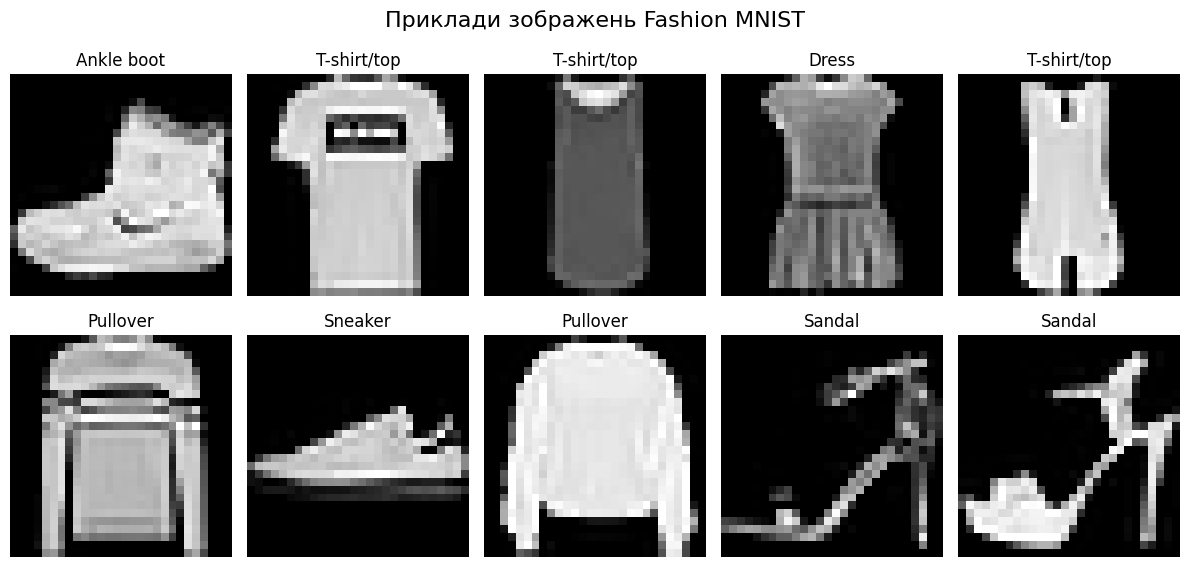

In [3]:

# Візуалізація 10 зображень Fashion MNIST

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])

    plt.axis('off')

plt.suptitle("Приклади зображень Fashion MNIST", fontsize=16)
plt.tight_layout()
plt.show()


### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [4]:

# Нормалізація даних

x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Перевірка типів даних
print("Тип навчальних даних:", x_train.dtype)
print("Тип тестових даних:", x_test.dtype)

# Перевірка діапазону значень
print("Мінімальне значення:", x_train.min())
print("Максимальне значення:", x_train.max())

print("Нормалізацію успішно виконано!")


Тип навчальних даних: float32
Тип тестових даних: float32
Мінімальне значення: 0.0
Максимальне значення: 1.0
Нормалізацію успішно виконано!


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:

# Побудова нейронної мережі

model = keras.Sequential([
    layers.Input(shape=(28, 28)),

    layers.Flatten(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),

    layers.Dense(10, activation='softmax')
])

# Компіляція моделі
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Модель успішно створена та скомпільована!")


Модель успішно створена та скомпільована!


### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [6]:

# Налаштування callback-функцій

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Навчання нейронної мережі

history = model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("Навчання моделі завершено!")


Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7767 - loss: 0.6252 - val_accuracy: 0.8388 - val_loss: 0.4339 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8411 - loss: 0.4372 - val_accuracy: 0.8567 - val_loss: 0.3882 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8572 - loss: 0.3939 - val_accuracy: 0.8633 - val_loss: 0.3703 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.8641 - loss: 0.3697 - val_accuracy: 0.8655 - val_loss: 0.3617 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8703 - loss: 0.3518 - val_accuracy: 0.8773 - val_loss: 0.3384 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8744 - loss: 0.3409 - val_accuracy: 0.8760 - val_loss: 0.3386 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8776 - loss: 0.330

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [7]:

# Аналіз архітектури нейронної мережі

model.summary()

# Кількість шарів
print("\nКількість шарів:", len(model.layers))

# Загальна кількість параметрів
print("Загальна кількість параметрів:", model.count_params())

# Кількість навчуваних параметрів
trainable_params = sum(
    np.prod(w.shape) for w in model.trainable_weights
)

print("Навчувані параметри:", trainable_params)



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 705,440 (2.69 MB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 470,294 (1.79 MB)


Кількість шарів: 6
Загальна кількість параметрів: 235146
Навчувані параметри: 235146


### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [8]:

# Збереження навченої моделі

model.save('Fashion_MNIST_Model.keras')

print("Модель успішно збережено!")
print("Назва файлу: Fashion_MNIST_Model.keras")


Модель успішно збережено!
Назва файлу: Fashion_MNIST_Model.keras


In [9]:

from google.colab import files

files.download('Fashion_MNIST_Model.keras')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

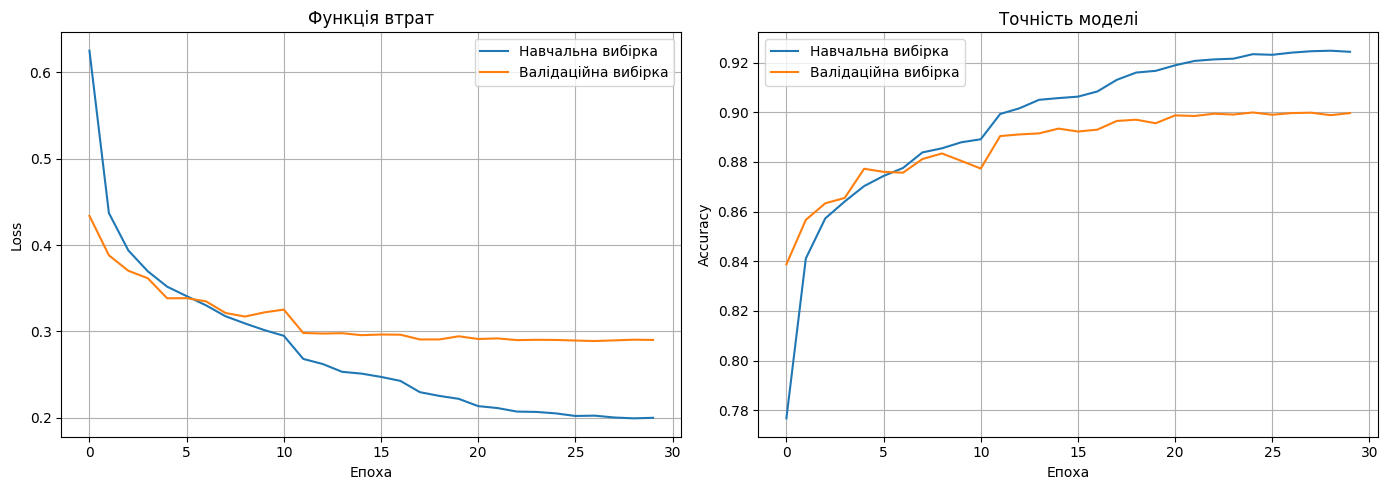

In [10]:

# Графіки навчання моделі

plt.figure(figsize=(14, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)

plt.plot(history.history['loss'], label='Навчальна вибірка')
plt.plot(history.history['val_loss'], label='Валідаційна вибірка')

plt.title('Функція втрат')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Графік точності
plt.subplot(1, 2, 2)

plt.plot(history.history['accuracy'], label='Навчальна вибірка')
plt.plot(history.history['val_accuracy'], label='Валідаційна вибірка')

plt.title('Точність моделі')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('task1_training_graphs.png', dpi=300)
plt.show()


### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [11]:

# Оцінювання моделі на тестовій вибірці

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nРезультати оцінювання:")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 4))
print("Test Accuracy (%):", round(test_accuracy * 100, 2), "%")

# Прогнозування класів
y_pred_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

# Класифікаційний звіт
print("\nКласифікаційний звіт:")

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

# Перевірка вимоги лабораторної роботи
if test_accuracy >= 0.87:
    print("Вимогу щодо точності 0.87 виконано!")
else:
    print("Вимогу щодо точності 0.87 не виконано.")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8963 - loss: 0.3157

Результати оцінювання:
Test Loss: 0.3157
Test Accuracy: 0.8963
Test Accuracy (%): 89.63 %

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top     0.8482    0.8550    0.8516      1000
     Trouser     0.9888    0.9740    0.9814      1000
    Pullover     0.7979    0.8210    0.8093      1000
       Dress     0.8963    0.9080    0.9021      1000
        Coat     0.8158    0.8240    0.8199      1000
      Sandal     0.9768    0.9700    0.9734      1000
       Shirt     0.7450    0.7100    0.7271      1000
     Sneaker     0.9442    0.9650    0.9545      1000
         Bag     0.9790    0.9780    0.9785      1000
  Ankle boot     0.9696    0.9580    0.9638      1000

    accuracy                         0.8963     10000
   macro avg     0.8962    0.8963    0.8962     10000
weighted avg     0.8962    0.8963    0.8962     10000

Вимогу щодо точності 0.87 виконано!


### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

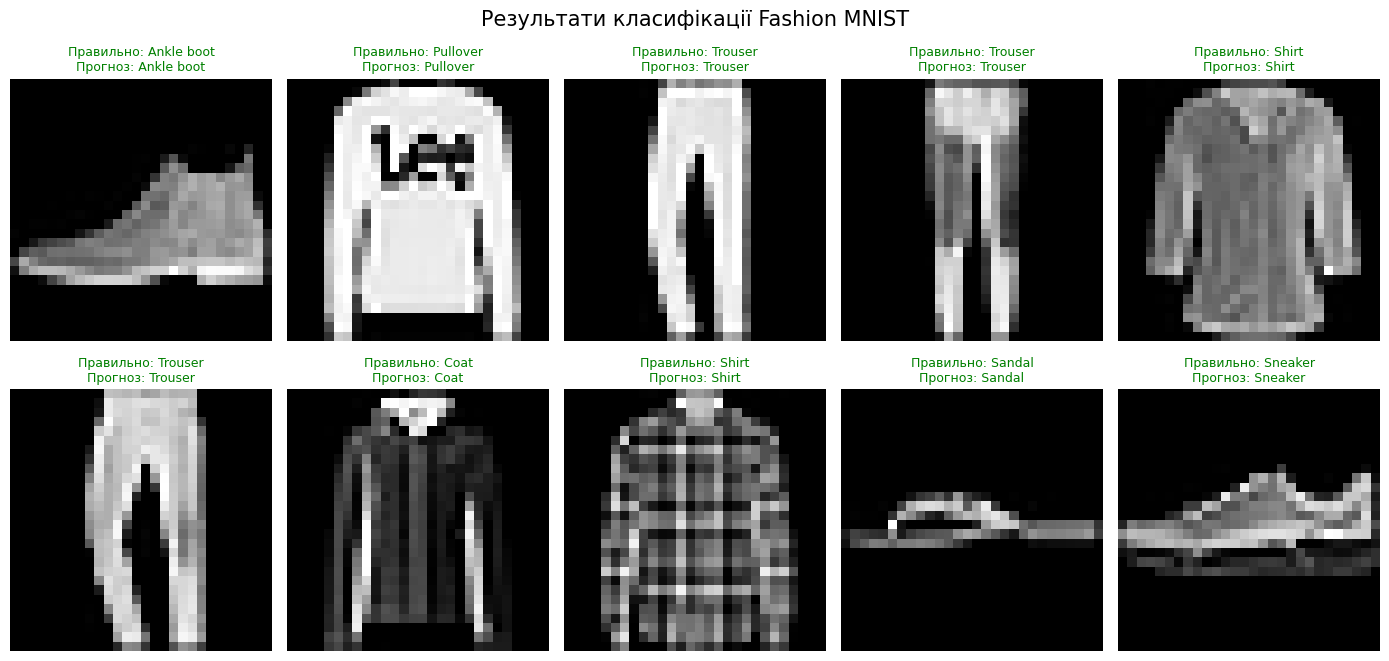

In [12]:

# Візуалізація прогнозів нейронної мережі

plt.figure(figsize=(14, 7))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    true_label = class_names[y_test[i]]
    predicted_label = class_names[y_pred[i]]

    color = 'green' if y_test[i] == y_pred[i] else 'red'

    plt.title(
        f"Правильно: {true_label}\nПрогноз: {predicted_label}",
        color=color,
        fontsize=9
    )

    plt.axis('off')

plt.suptitle("Результати класифікації Fashion MNIST", fontsize=15)
plt.tight_layout()
plt.savefig('task1_predictions.png', dpi=300)
plt.show()


**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**
У результаті виконання першого завдання було створено та навчено нейронну мережу для класифікації зображень набору Fashion MNIST. Модель складалася з двох прихованих повнозв'язних шарів на 256 та 128 нейронів, а також шарів Dropout для зменшення перенавчання. Навчання проводилося протягом 30 епох з використанням оптимізатора Adam. Точність моделі на тестовій вибірці склала 89.63%, а значення функції втрат — 0.3157. Найкраще модель розпізнавала штани, сумки та сандалі. Найскладнішим для класифікації виявився клас Shirt. Отже, побудована нейронна мережа показала достатньо високу точність класифікації зображень.
_..._

# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [13]:

# Встановлення Keras Tuner

!pip install -q keras-tuner

# Імпорт необхідних компонентів

import keras_tuner as kt

from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

from keras_tuner import RandomSearch

print("Keras Tuner version:", kt.__version__)
print("Бібліотеку успішно встановлено та імпортовано!")


Keras Tuner version: 1.4.8
Бібліотеку успішно встановлено та імпортовано!


### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [14]:

# Розділення навчальних даних на навчальну та валідаційну вибірки

x_train_tuner, x_val_tuner, y_train_tuner, y_val_tuner = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Перевірка розмірів вибірок

print("Навчальні зображення:", x_train_tuner.shape)
print("Навчальні мітки:", y_train_tuner.shape)

print("Валідаційні зображення:", x_val_tuner.shape)
print("Валідаційні мітки:", y_val_tuner.shape)

print("Тестові зображення:", x_test.shape)
print("Тестові мітки:", y_test.shape)


Навчальні зображення: (48000, 28, 28)
Навчальні мітки: (48000,)
Валідаційні зображення: (12000, 28, 28)
Валідаційні мітки: (12000,)
Тестові зображення: (10000, 28, 28)
Тестові мітки: (10000,)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [15]:

# Функція побудови моделі з гіперпараметрами

def build_model(hp):

    model = keras.Sequential()

    model.add(layers.Input(shape=(28, 28)))
    model.add(Flatten())

    # Пошук кількості прихованих шарів
    num_layers = hp.Int(
        'num_layers',
        min_value=1,
        max_value=3,
        step=1
    )

    # Створення прихованих шарів
    for i in range(num_layers):

        units = hp.Int(
            f'units_{i}',
            min_value=32,
            max_value=512,
            step=32
        )

        model.add(
            Dense(
                units,
                activation='relu',
                kernel_regularizer=l2(0.001)
            )
        )

        model.add(Dropout(0.3))

    # Вихідний шар
    model.add(Dense(10, activation='softmax'))

    # Пошук швидкості навчання
    learning_rate = hp.Choice(
        'learning_rate',
        values=[0.01, 0.001, 0.0001]
    )

    # Компіляція моделі
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


print("Функцію build_model(hp) успішно створено!")


Функцію build_model(hp) успішно створено!


### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [16]:

# Створення об'єкта RandomSearch

tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='fashion_mnist_tuner',
    project_name='hyperparameter_search',
    overwrite=True,
    seed=42
)

print("RandomSearch успішно створено!")

# Виведення простору гіперпараметрів
tuner.search_space_summary()


RandomSearch успішно створено!
Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [17]:

# Callback-функції для пошуку

tuner_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

tuner_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Запуск автоматизованого пошуку

tuner.search(
    x_train_tuner,
    y_train_tuner,
    epochs=30,
    batch_size=128,
    validation_data=(x_val_tuner, y_val_tuner),
    callbacks=[
        tuner_early_stopping,
        tuner_reduce_lr
    ],
    verbose=1
)

print("Пошук гіперпараметрів завершено!")


Trial 3 Complete [00h 01m 50s]
val_accuracy: 0.878083348274231

Best val_accuracy So Far: 0.8941666483879089
Total elapsed time: 00h 06m 46s
Пошук гіперпараметрів завершено!


In [18]:

# Отримання найкращих гіперпараметрів

best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("НАЙКРАЩІ ГІПЕРПАРАМЕТРИ")
print("--------------------------------")

print("Кількість прихованих шарів:",
      best_hp.get('num_layers'))

for i in range(best_hp.get('num_layers')):
    print(
        f"Кількість нейронів у шарі {i + 1}:",
        best_hp.get(f'units_{i}')
    )

print("Швидкість навчання:",
      best_hp.get('learning_rate'))

# Отримання найкращої моделі
best_model = tuner.get_best_models(num_models=1)[0]

print("\nАрхітектура найкращої моделі:")
best_model.summary()


НАЙКРАЩІ ГІПЕРПАРАМЕТРИ
--------------------------------
Кількість прихованих шарів: 1
Кількість нейронів у шарі 1: 480
Швидкість навчання: 0.001

Архітектура найкращої моделі:


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 381,610 (1.46 MB)

 Trainable params: 381,610 (1.46 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:

# Створення моделі з найкращими гіперпараметрами

best_model = build_model(best_hp)

# Callback-функції для фінального навчання

final_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

final_reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

# Перенавчання найкращої моделі

best_history = best_model.fit(
    x_train,
    y_train,
    epochs=30,
    batch_size=128,
    validation_split=0.2,
    callbacks=[
        final_early_stopping,
        final_reduce_lr
    ],
    verbose=1
)

print("Навчання найкращої моделі завершено!")


Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.7980 - loss: 0.9144 - val_accuracy: 0.8403 - val_loss: 0.6856 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8415 - loss: 0.6185 - val_accuracy: 0.8539 - val_loss: 0.5560 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.8485 - loss: 0.5451 - val_accuracy: 0.8513 - val_loss: 0.5237 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8518 - loss: 0.5124 - val_accuracy: 0.8553 - val_loss: 0.4927 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.8550 - loss: 0.4961 - val_accuracy: 0.8575 - val_loss: 0.4874 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.8560 - loss: 0.4876 - val_accuracy: 0.8600 - val_loss: 0.4738 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8558 - loss:

In [20]:

# Збереження оптимізованої моделі

best_model.save('Fashion_MNIST_Best_Model.keras')

print("Найкращу модель збережено!")


Найкращу модель збережено!


### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

In [21]:

# Фінальне оцінювання найкращої моделі

best_test_loss, best_test_accuracy = best_model.evaluate(
    x_test,
    y_test,
    verbose=1
)

print("\nРЕЗУЛЬТАТИ НАЙКРАЩОЇ МОДЕЛІ")
print("--------------------------------")

print("Test Loss:", round(best_test_loss, 4))
print("Test Accuracy:", round(best_test_accuracy, 4))
print("Test Accuracy (%):", round(best_test_accuracy * 100, 2), "%")

# Класифікаційний звіт
best_y_pred_prob = best_model.predict(x_test, verbose=0)
best_y_pred = np.argmax(best_y_pred_prob, axis=1)

print("\nКласифікаційний звіт:")
print(classification_report(
    y_test,
    best_y_pred,
    target_names=class_names,
    digits=4
))


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8790 - loss: 0.3862

РЕЗУЛЬТАТИ НАЙКРАЩОЇ МОДЕЛІ
--------------------------------
Test Loss: 0.3862
Test Accuracy: 0.879
Test Accuracy (%): 87.9 %

Класифікаційний звіт:
              precision    recall  f1-score   support

 T-shirt/top     0.8704    0.7790    0.8222      1000
     Trouser     0.9898    0.9700    0.9798      1000
    Pullover     0.7889    0.8110    0.7998      1000
       Dress     0.8733    0.8960    0.8845      1000
        Coat     0.8074    0.7880    0.7976      1000
      Sandal     0.9617    0.9540    0.9578      1000
       Shirt     0.6667    0.7160    0.6905      1000
     Sneaker     0.9298    0.9540    0.9418      1000
         Bag     0.9596    0.9730    0.9662      1000
  Ankle boot     0.9596    0.9490    0.9542      1000

    accuracy                         0.8790     10000
   macro avg     0.8807    0.8790    0.8794     10000
weighted avg     0.8807    0.8790    0.8794     10000



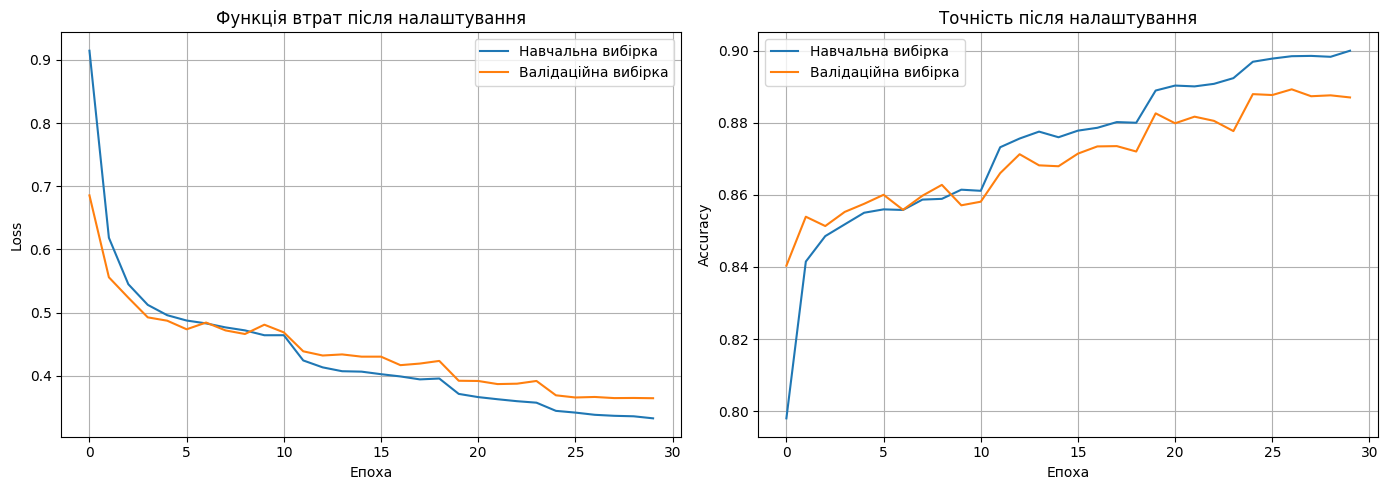

In [22]:

# Графіки навчання оптимізованої моделі

plt.figure(figsize=(14, 5))

# Графік функції втрат
plt.subplot(1, 2, 1)

plt.plot(
    best_history.history['loss'],
    label='Навчальна вибірка'
)

plt.plot(
    best_history.history['val_loss'],
    label='Валідаційна вибірка'
)

plt.title('Функція втрат після налаштування')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Графік точності
plt.subplot(1, 2, 2)

plt.plot(
    best_history.history['accuracy'],
    label='Навчальна вибірка'
)

plt.plot(
    best_history.history['val_accuracy'],
    label='Валідаційна вибірка'
)

plt.title('Точність після налаштування')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('task2_tuned_graphs.png', dpi=300)
plt.show()


In [23]:

import pandas as pd

# Кількість прихованих шарів першої моделі
task1_hidden_layers = 2

# Кількість нейронів першої моделі
task1_neurons = "256, 128"

# Швидкість навчання першої моделі
task1_lr = 0.001

# Кількість прихованих шарів другої моделі
task2_hidden_layers = best_hp.get('num_layers')

# Кількість нейронів другої моделі
task2_neurons = ", ".join(
    str(best_hp.get(f'units_{i}'))
    for i in range(task2_hidden_layers)
)

# Швидкість навчання другої моделі
task2_lr = best_hp.get('learning_rate')

# Формування порівняльної таблиці
comparison = pd.DataFrame({
    'Показник': [
        'Кількість прихованих шарів',
        'Кількість нейронів',
        'Швидкість навчання',
        'Точність на тестовій вибірці (accuracy)',
        'Втрати на тестовій вибірці (loss)',
        'Кількість епох навчання'
    ],

    'Модель із завдання 1': [
        task1_hidden_layers,
        task1_neurons,
        task1_lr,
        round(test_accuracy, 4),
        round(test_loss, 4),
        len(history.history['loss'])
    ],

    'Модель після Keras Tuner': [
        task2_hidden_layers,
        task2_neurons,
        task2_lr,
        round(best_test_accuracy, 4),
        round(best_test_loss, 4),
        len(best_history.history['loss'])
    ]
})

print("ПОРІВНЯННЯ ДВОХ НЕЙРОННИХ МЕРЕЖ")
display(comparison)


ПОРІВНЯННЯ ДВОХ НЕЙРОННИХ МЕРЕЖ


,Показник,Модель із завдання 1,Модель після Keras Tuner
0,Кількість прихованих шарів,2,1
1,Кількість нейронів,"256, 128",480
2,Швидкість навчання,0.001,0.001
3,Точність на тестовій вибірці (accuracy),0.8963,0.879
4,Втрати на тестовій вибірці (loss),0.3157,0.3862
5,Кількість епох навчання,30,30


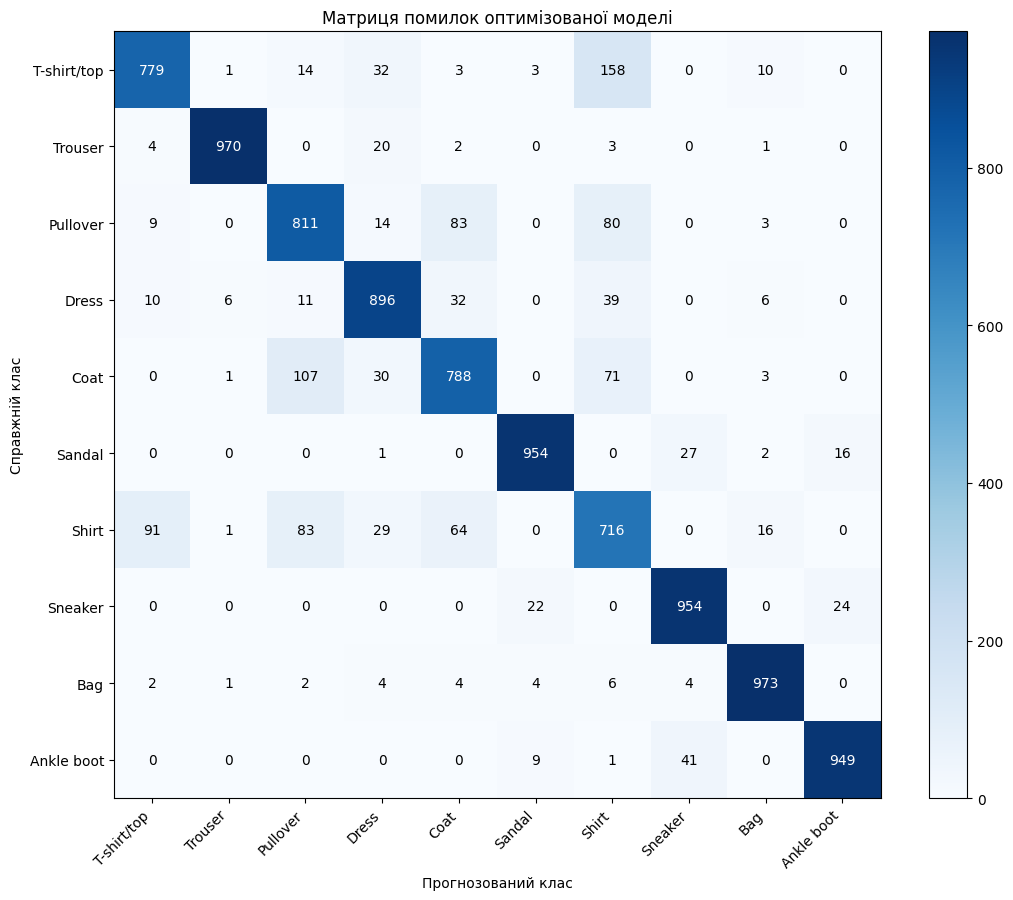

Класи від найскладнішого до найлегшого:


,Клас,Recall
6,Shirt,0.716
0,T-shirt/top,0.779
4,Coat,0.788
2,Pullover,0.811
3,Dress,0.896
9,Ankle boot,0.949
7,Sneaker,0.954
5,Sandal,0.954
1,Trouser,0.970
8,Bag,0.973



Найскладніші класи:
          Клас  Recall
6        Shirt   0.716
0  T-shirt/top   0.779
4         Coat   0.788


In [24]:

# Матриця помилок для оптимізованої моделі

cm = confusion_matrix(y_test, best_y_pred)

plt.figure(figsize=(11, 9))

plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Матриця помилок оптимізованої моделі')
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=45,
    ha='right'
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel('Прогнозований клас')
plt.ylabel('Справжній клас')

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j, i, str(cm[i, j]),
            ha='center',
            va='center',
            color='black' if cm[i, j] < cm.max() * 0.6 else 'white'
        )

plt.tight_layout()
plt.savefig('task2_confusion_matrix.png', dpi=300)
plt.show()

# Визначення класів із найнижчим recall

class_recall = np.diag(cm) / cm.sum(axis=1)

recall_results = pd.DataFrame({
    'Клас': class_names,
    'Recall': class_recall
})

recall_results = recall_results.sort_values(
    by='Recall',
    ascending=True
)

print("Класи від найскладнішого до найлегшого:")
display(recall_results)

print("\nНайскладніші класи:")
print(recall_results.head(3))


In [25]:

# Підсумкові результати лабораторної роботи

print("=" * 55)
print("ПІДСУМКОВІ РЕЗУЛЬТАТИ ЛАБОРАТОРНОЇ РОБОТИ №10")
print("=" * 55)

print("\nЗАВДАННЯ 1")
print("Accuracy:", round(test_accuracy, 4))
print("Loss:", round(test_loss, 4))
print("Кількість епох:", len(history.history['loss']))

print("\nЗАВДАННЯ 2")
print("Accuracy:", round(best_test_accuracy, 4))
print("Loss:", round(best_test_loss, 4))
print("Кількість епох:", len(best_history.history['loss']))

print("\nНАЙКРАЩІ ГІПЕРПАРАМЕТРИ")
print("Прихованих шарів:", task2_hidden_layers)
print("Нейронів:", task2_neurons)
print("Learning rate:", task2_lr)

print("\nПОРІВНЯННЯ")
difference = best_test_accuracy - test_accuracy

print("Зміна точності:", round(difference, 4))
print("Зміна точності у відсоткових пунктах:",
      round(difference * 100, 2))

if test_accuracy >= 0.87:
    print("Завдання 1: вимогу 0.87 виконано.")
else:
    print("Завдання 1: вимогу 0.87 не виконано.")

if best_test_accuracy > test_accuracy:
    print("Keras Tuner покращив тестову точність.")
elif best_test_accuracy < test_accuracy:
    print("Після налаштування тестова точність зменшилася.")
else:
    print("Тестова точність залишилася незмінною.")

print("=" * 55)


ПІДСУМКОВІ РЕЗУЛЬТАТИ ЛАБОРАТОРНОЇ РОБОТИ №10

ЗАВДАННЯ 1
Accuracy: 0.8963
Loss: 0.3157
Кількість епох: 30

ЗАВДАННЯ 2
Accuracy: 0.879
Loss: 0.3862
Кількість епох: 30

НАЙКРАЩІ ГІПЕРПАРАМЕТРИ
Прихованих шарів: 1
Нейронів: 480
Learning rate: 0.001

ПОРІВНЯННЯ
Зміна точності: -0.0173
Зміна точності у відсоткових пунктах: -1.73
Завдання 1: вимогу 0.87 виконано.
Після налаштування тестова точність зменшилася.


In [26]:

# Створення архіву з результатами лабораторної роботи

import zipfile
import os

files_to_save = [
    'Fashion_MNIST_Model.keras',
    'Fashion_MNIST_Best_Model.keras',
    'task1_training_graphs.png',
    'task1_predictions.png',
    'task2_tuned_graphs.png',
    'task2_confusion_matrix.png'
]

with zipfile.ZipFile(
    'Lab10_Results.zip',
    'w',
    zipfile.ZIP_DEFLATED
) as zipf:

    for filename in files_to_save:
        if os.path.exists(filename):
            zipf.write(filename)

print("Архів із результатами створено!")


Архів із результатами створено!


In [27]:

from google.colab import files

files.download('Lab10_Results.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:

# Автоматичне формування висновків

hardest_classes = ", ".join(
    recall_results.head(3)['Клас'].tolist()
)

if test_accuracy >= 0.87:
    requirement = "виконано"
else:
    requirement = "не виконано"

if best_test_accuracy > test_accuracy:
    improvement = (
        f"Точність покращилася на "
        f"{(best_test_accuracy - test_accuracy) * 100:.2f} "
        f"відсоткових пунктів."
    )
elif best_test_accuracy < test_accuracy:
    improvement = (
        f"Точність зменшилася на "
        f"{(test_accuracy - best_test_accuracy) * 100:.2f} "
        f"відсоткових пунктів."
    )
else:
    improvement = "Точність залишилася незмінною."

print("ВИСНОВКИ")
print("=" * 60)

print(
    f"1. У першому завданні отримано тестову точність "
    f"{test_accuracy:.4f} ({test_accuracy * 100:.2f}%). "
    f"Вимогу щодо мінімальної точності 0,87 {requirement}."
)

print(
    f"\n2. Після використання Keras Tuner отримано точність "
    f"{best_test_accuracy:.4f} "
    f"({best_test_accuracy * 100:.2f}%). {improvement}"
)

print(
    f"\n3. Найкраща конфігурація містить "
    f"{task2_hidden_layers} прихованих шарів, "
    f"кількість нейронів: {task2_neurons}, "
    f"швидкість навчання: {task2_lr}."
)

print(
    "\n4. Найскладнішими для класифікації виявилися класи: "
    f"{hardest_classes}. "
    "Це пов'язано зі схожістю зовнішнього вигляду деяких "
    "категорій одягу."
)

print(
    "\nРезультати можуть відрізнятися між запусками через "
    "випадкову ініціалізацію ваг, порядок навчання та "
    "випадковий вибір конфігурацій під час пошуку."
)

print("=" * 60)


ВИСНОВКИ
1. У першому завданні отримано тестову точність 0.8963 (89.63%). Вимогу щодо мінімальної точності 0,87 виконано.

2. Після використання Keras Tuner отримано точність 0.8790 (87.90%). Точність зменшилася на 1.73 відсоткових пунктів.

3. Найкраща конфігурація містить 1 прихованих шарів, кількість нейронів: 480, швидкість навчання: 0.001.

4. Найскладнішими для класифікації виявилися класи: Shirt, T-shirt/top, Coat. Це пов'язано зі схожістю зовнішнього вигляду деяких категорій одягу.

Результати можуть відрізнятися між запусками через випадкову ініціалізацію ваг, порядок навчання та випадковий вибір конфігурацій під час пошуку.


# Висновки. Порівняння моделей

Під час виконання лабораторної роботи було побудовано та навчено дві нейронні мережі засобами бібліотеки Keras для класифікації зображень набору Fashion MNIST.

У першому завданні було створено нейронну мережу з двома прихованими повнозв'язними шарами на 256 та 128 нейронів. Точність моделі на тестовій вибірці склала 89.63%, а значення функції втрат — 0.3157.

У другому завданні було використано Keras Tuner для автоматичного підбору гіперпараметрів. У результаті було отримано модель з одним прихованим шаром на 480 нейронів. Її точність на тестовій вибірці склала 87.90%, а функція втрат — 0.3862.

Порівняння показало, що початкова модель виявилася ефективнішою за оптимізовану. Це свідчить про те, що автоматичне налаштування гіперпараметрів не завжди гарантує покращення результатів, особливо за невеликої кількості випробувань.

Також було визначено, що найскладнішим для розпізнавання класом є Shirt, а найкраще розпізнається клас Bag.

У результаті виконання роботи було отримано практичні навички створення, навчання та оцінювання нейронних мереж, використання регуляризації та автоматичного налаштування гіперпараметрів за допомогою Keras Tuner.

Мету лабораторної роботи досягнуто.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.